# Customer Churn Prediction

Predicting whether a telecom customer will leave the company (churn) using the Telco Customer Churn dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline

## Load Data

In [2]:
data = pd.read_csv("data/Telco-Customer-Churn.csv")
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print(data.shape)
data.info()

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


## Data Cleaning

In [4]:
data = data.drop("customerID", axis=1)

In [5]:
# TotalCharges is text because some rows have a blank space
blank_rows = data[data["TotalCharges"] == " "]
print("blank rows:", len(blank_rows))
blank_rows[["tenure", "MonthlyCharges", "TotalCharges"]]

blank rows: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,
753,0,20.25,
936,0,80.85,
1082,0,25.75,
1340,0,56.05,
3331,0,19.85,
3826,0,25.35,
4380,0,20.00,
5218,0,19.70,
6670,0,73.35,


In [6]:
# all blank rows have tenure 0, they are new customers with no bill yet, so 0 is correct
data["TotalCharges"] = data["TotalCharges"].replace(" ", "0").astype(float)
data.isnull().sum().sum()

np.int64(0)

## EDA

Churn
No     5174
Yes    1869
Name: count, dtype: int64


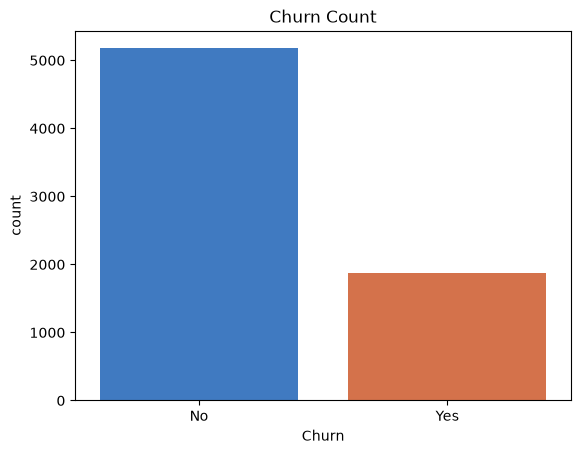

In [7]:
colors = {"No": "#2a78d6", "Yes": "#eb6834"}

print(data["Churn"].value_counts())
sns.countplot(x="Churn", hue="Churn", data=data, palette=colors)
plt.title("Churn Count")
plt.show()

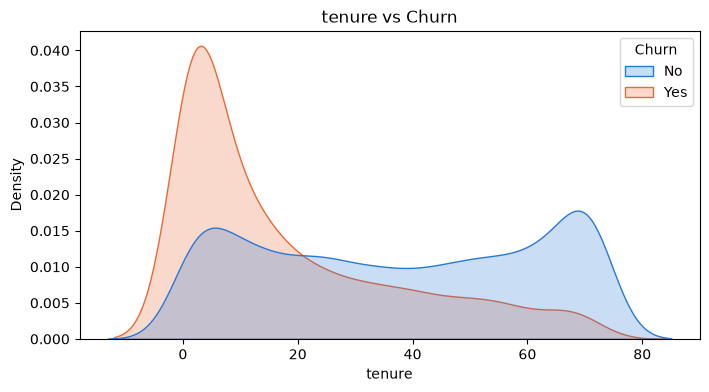

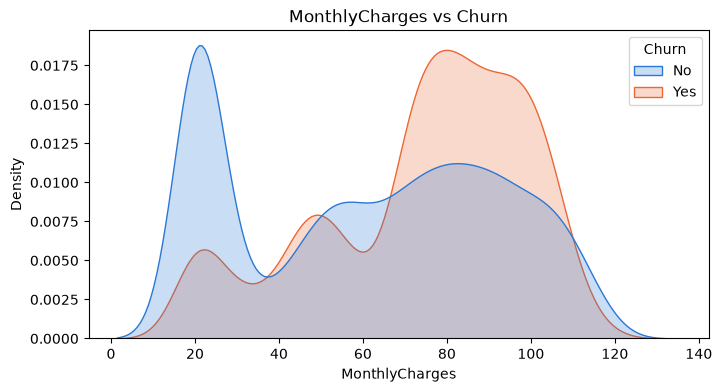

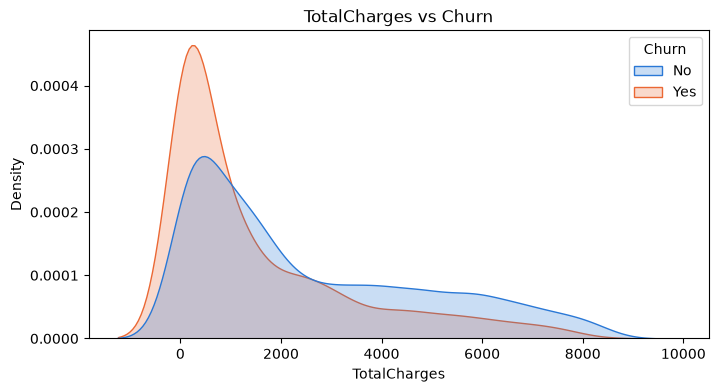

In [8]:
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    plt.figure(figsize=(8, 4))
    sns.kdeplot(data=data, x=col, hue="Churn", fill=True, common_norm=False, palette=colors)
    plt.title(col + " vs Churn")
    plt.show()

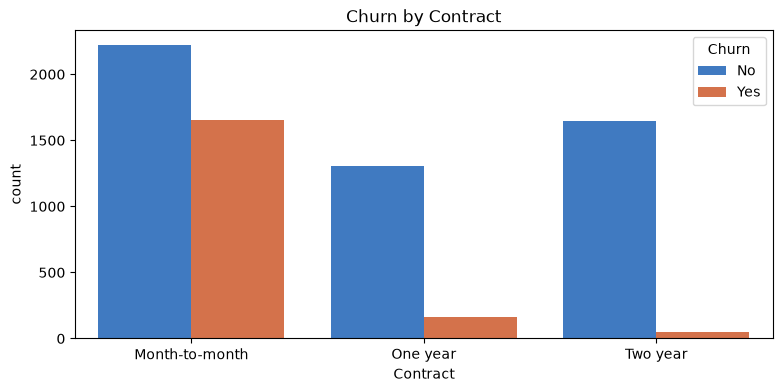

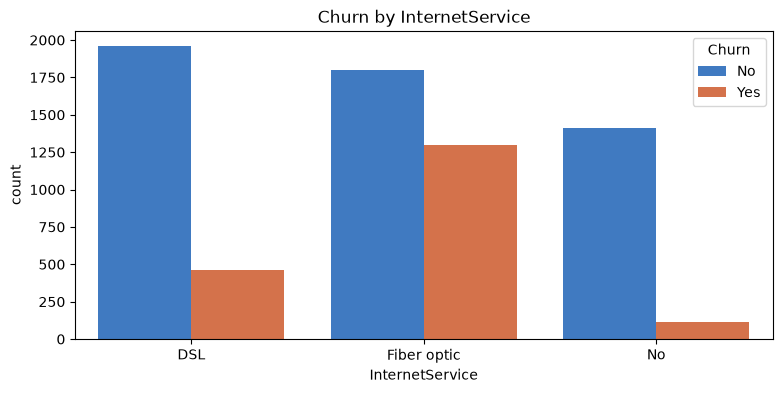

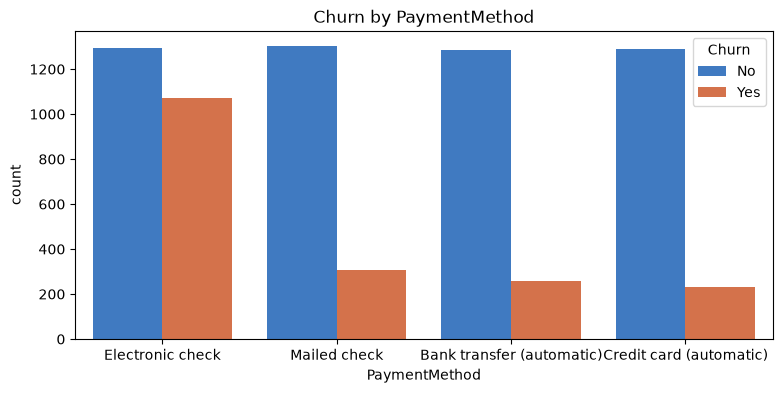

In [9]:
for col in ["Contract", "InternetService", "PaymentMethod"]:
    plt.figure(figsize=(9, 4))
    sns.countplot(x=col, hue="Churn", data=data, palette=colors)
    plt.title("Churn by " + col)
    plt.show()

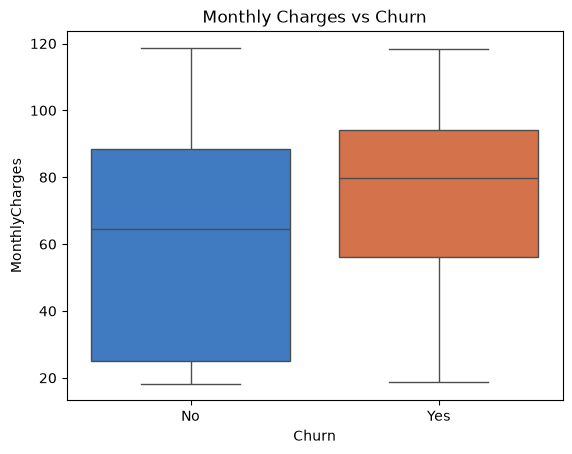

In [10]:
sns.boxplot(x="Churn", y="MonthlyCharges", hue="Churn", data=data, palette=colors)
plt.title("Monthly Charges vs Churn")
plt.show()

**Observations**
- Only about 26% customers churned, so the data is imbalanced
- Month-to-month contract, fiber optic and electronic check customers churn the most
- New customers (low tenure) and customers with high monthly charges churn more

## Encoding

In [11]:
data = data.replace("No internet service", "No")
data = data.replace("No phone service", "No")

yes_no_cols = ["Partner", "Dependents", "PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
               "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling", "Churn"]

for col in yes_no_cols:
    data[col] = data[col].map({"Yes": 1, "No": 0})

data["gender"] = data["gender"].map({"Female": 0, "Male": 1})

# InternetService, Contract and PaymentMethod are one-hot encoded later, after SMOTE
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


## Train Test Split

In [12]:
X = data.drop("Churn", axis=1)
y = data["Churn"]

# stratify keeps the same churn ratio in train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


## Scaling and SMOTE

In [13]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
multi_cols = ["InternetService", "Contract", "PaymentMethod"]
cat_cols = [col for col in X.columns if col not in num_cols]

# scale only the number columns, other columns stay the same
scaler = ColumnTransformer([("scale", MinMaxScaler(), num_cols)], remainder="passthrough", verbose_feature_names_out=False)
scaler.set_output(transform="pandas")

X_train_scaled = scaler.fit_transform(X_train)
X_train_scaled.head()

,tenure,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
3738,0.486111,0.306926,0.195934,1,0,0,0,0,0,DSL,0,0,1,0,1,1,Month-to-month,0,Electronic check
3151,0.208333,0.565022,0.132594,1,0,1,1,1,0,Fiber optic,1,0,0,0,0,0,Month-to-month,0,Mailed check
4860,0.180556,0.220727,0.067975,1,0,1,1,0,0,DSL,1,1,0,1,0,0,Two year,0,Mailed check
3867,0.361111,0.549078,0.219429,0,0,1,0,1,0,DSL,0,1,1,0,1,1,Two year,1,Credit card (automatic)
3810,0.013889,0.260588,0.005130,1,0,1,1,1,0,DSL,0,0,0,0,0,0,Month-to-month,0,Electronic check


In [14]:
print("before smote:")
print(y_train.value_counts())

# SMOTENC keeps category columns as real values, normal SMOTE was giving values like gender = 0.5
smote = SMOTENC(categorical_features=cat_cols, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("after smote:")
print(y_train_smote.value_counts())

before smote:
Churn
0    4139
1    1495
Name: count, dtype: int64


after smote:
Churn
0    4139
1    4139
Name: count, dtype: int64


In [15]:
# checking the new rows made by smote
new_rows = X_train_smote.iloc[len(X_train_scaled):]
print("new rows:", len(new_rows))
print(new_rows["gender"].value_counts())
print(new_rows["Contract"].value_counts())

new rows: 2644
gender
0    1333
1    1311
Name: count, dtype: int64
Contract
Month-to-month    2414
One year           195
Two year            35
Name: count, dtype: int64


## Model Comparison with Cross Validation

In [16]:
encoder = ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), multi_cols)], remainder="passthrough", verbose_feature_names_out=False)

# everything is inside the pipeline so it only learns from the training folds
def build_pipeline(model, use_smote):
    steps = [("scaler", scaler)]
    if use_smote:
        steps.append(("smote", SMOTENC(categorical_features=cat_cols, random_state=42)))
    steps.append(("encoder", encoder))
    steps.append(("model", model))
    return Pipeline(steps)

In [17]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42),
}

# same models with class_weight, another way to handle imbalance without making new rows
weighted_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "SVM": SVC(class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, class_weight="balanced"),
}

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

results = []
for name in models:
    for data_type in ["Normal", "SMOTE", "Class Weight"]:
        if data_type == "Class Weight":
            pipe = build_pipeline(weighted_models[name], use_smote=False)
        else:
            pipe = build_pipeline(models[name], use_smote=(data_type == "SMOTE"))

        scores = cross_validate(pipe, X_train, y_train, cv=kfold, scoring=metrics)
        results.append([name, data_type] + [scores["test_" + m].mean() for m in metrics])

results = pd.DataFrame(results, columns=["Model", "Data", "Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])
results.sort_values("F1", ascending=False).round(3)

,Model,Data,Accuracy,Precision,Recall,F1,ROC-AUC
7,Random Forest,SMOTE,0.779,0.565,0.728,0.636,0.840
8,Random Forest,Class Weight,0.767,0.544,0.760,0.634,0.844
2,Logistic Regression,Class Weight,0.749,0.518,0.798,0.628,0.845
1,Logistic Regression,SMOTE,0.758,0.531,0.767,0.627,0.840
5,SVM,Class Weight,0.748,0.517,0.783,0.623,0.826
4,SVM,SMOTE,0.764,0.542,0.714,0.616,0.818
0,Logistic Regression,Normal,0.801,0.651,0.540,0.590,0.846
3,SVM,Normal,0.802,0.665,0.512,0.578,0.807
6,Random Forest,Normal,0.800,0.664,0.505,0.573,0.842


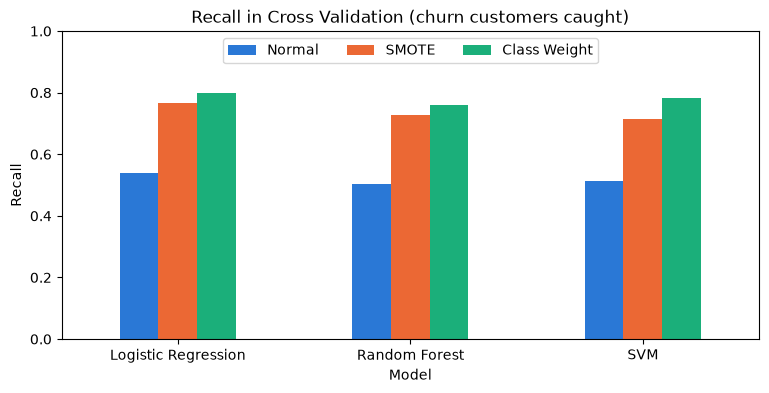

In [18]:
recall_table = results.pivot(index="Model", columns="Data", values="Recall")[["Normal", "SMOTE", "Class Weight"]]
recall_table.plot(kind="bar", figsize=(9, 4), color=["#2a78d6", "#eb6834", "#1baf7a"])
plt.title("Recall in Cross Validation (churn customers caught)")
plt.xticks(rotation=0)
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.legend(ncol=3, loc="upper center")
plt.show()

## Hyperparameter Tuning

In [19]:
best = results.sort_values("F1", ascending=False).iloc[0]
print("best in comparison:", best["Model"], "+", best["Data"])

best in comparison: Random Forest + SMOTE


In [20]:
# trying different settings for random forest + smote, the best one from the table
param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [5, 10, 15],
    "model__min_samples_leaf": [1, 5, 10],
}

search = GridSearchCV(build_pipeline(models["Random Forest"], use_smote=True), param_grid, cv=kfold, scoring="f1", n_jobs=-1)
search.fit(X_train, y_train)

print("best settings:", search.best_params_)
print("best F1:", round(search.best_score_, 3))

best settings: {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
best F1: 0.639


In [21]:
tuning = pd.DataFrame(search.cv_results_["params"])
tuning["F1"] = search.cv_results_["mean_test_score"]
tuning.sort_values("F1", ascending=False).head()

,model__max_depth,model__min_samples_leaf,model__n_estimators,F1
13,10,5,200,0.639358
12,10,5,100,0.639230
17,10,10,300,0.639157
15,10,10,100,0.638842
14,10,5,300,0.638663


## Best Model

In [22]:
# grid search already trained the best settings on the full training data
best_model = search.best_estimator_

# test data is used only here, after the model is chosen
pred = best_model.predict(X_test)
churn_proba = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred))
print("ROC-AUC:", round(roc_auc_score(y_test, churn_proba), 3))

              precision    recall  f1-score   support

           0       0.88      0.78      0.83      1035
           1       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409

ROC-AUC: 0.838


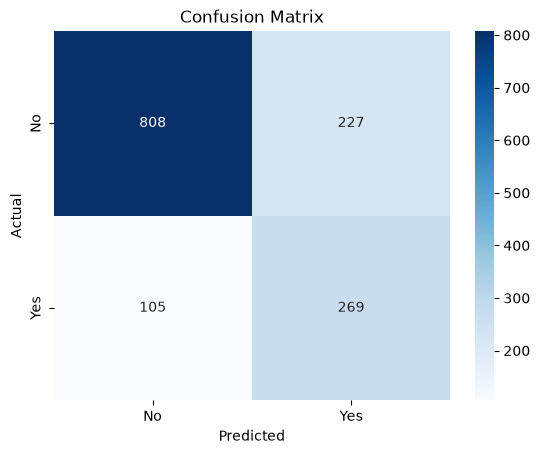

In [23]:
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

## Threshold Tuning


In [24]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score

# probability for every training row, from a model that did not see that row
train_proba = cross_val_predict(best_model, X_train, y_train, cv=kfold, method="predict_proba")[:, 1]

In [25]:
thresholds = [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]
f1_scores = []

for t in thresholds:
    train_pred = (train_proba >= t).astype(int)
    score = f1_score(y_train, train_pred)
    f1_scores.append(score)
    print(t, round(score, 3))

best_threshold = thresholds[f1_scores.index(max(f1_scores))]
print("best threshold:", best_threshold)

0.3 0.6
0.35 0.613
0.4 0.625
0.45 0.635
0.5 0.639
0.55 0.635
0.6 0.613
best threshold: 0.5


In [26]:
# threshold was chosen on training data, the test set is only used to see the result
test_pred = (churn_proba >= best_threshold).astype(int)
print(classification_report(y_test, test_pred))


              precision    recall  f1-score   support

           0       0.88      0.78      0.83      1035
           1       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



## Important Features

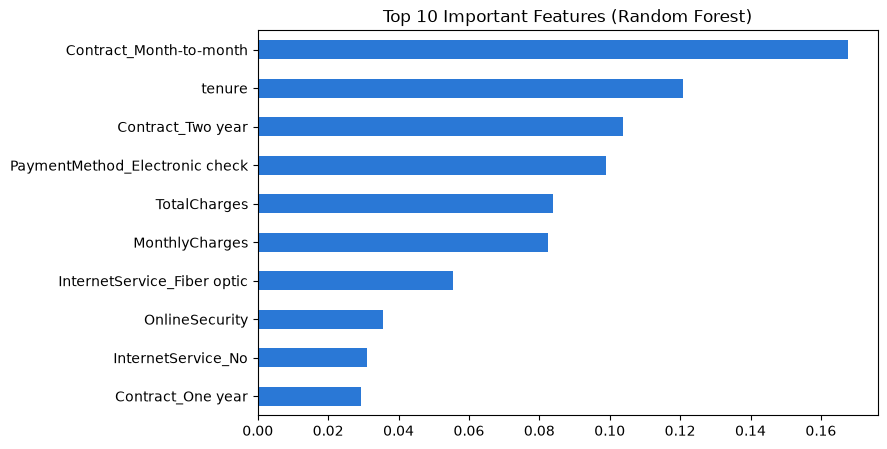

In [27]:
feature_names = best_model.named_steps["encoder"].get_feature_names_out()
importance = pd.Series(best_model.named_steps["model"].feature_importances_, index=feature_names).sort_values()

importance.tail(10).plot(kind="barh", figsize=(8, 5), color="#2a78d6")
plt.title("Top 10 Important Features (Random Forest)")
plt.show()

## Save Model

In [28]:
# scaler and encoder are inside the pipeline, so one file is enough
with open("churn_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

In [29]:
with open("churn_model.pkl", "rb") as f:
    loaded_model = pickle.load(f)

print("same predictions:", (loaded_model.predict(X_test) == pred).all())

# the model takes a customer in the same form as the cleaned data
new_customer = X_test.head(1)
print("prediction for this customer:", loaded_model.predict(new_customer)[0])

same predictions: True
prediction for this customer: 0
